# 7. Benzene: MOs and Symmetry

Benzene is the **iconic** organic molecule. Imagine if I had to design a superhero outfit for “Chemistry Man” (He can change phase from solid to liquid, but he requires a heat source to do so). I would choose a **hexagon**, representing the planar benzene structure, as the superhero **symbol** emblazoned on the cape.

We have already created a **molecular orbital diagram** for the &pi;-system of benzene using SHMO theory. Let us now **repeat** that exercise using *GAMESS*.

## Learning Goals

In this exercise, we will accomplish the following…

1.	Use *MacMolPlt* to **build** benzene. We will use **symmetry** and the *D<sub>6h</sub>* point group. We will also use the *C<sub>2v</sub>* point group.
2.	We will then **optimize** the structure and **visualize** the orbitals.
3.	This will be a good system to demonstrate the benefits of symmetry. We will try an expensive energy calculation using the two point groups above and the *C<sub>1</sub>* point group.

### Settings

Run this cell first. It loads the book's helper module, `gamess_tools.py`, which finds *GAMESS* using the location you set in `gamess_settings.py` on the [setup page](1_Setup.ipynb). The `.log` files are written into the `runs/ch6/` folder next to this notebook.

Some jobs on this page take minutes, not seconds. The book comes with their log files in `runs/ch6/`, and with `RERUN = False` the notebook reads those files instead of running the jobs again. Set `RERUN = True` to run everything on your own computer and time it yourself.

:::{note} Mac users: after a restart
macOS resets the shared-memory limits every time you restart. If a *GAMESS* job stops with a fatal error and the `.log` file shows `shmget returned an error`, set the limits again (see [Raise shared-memory limits](#shared-memory-limits) in [](1D-CompileInstruction2024.md)).
:::

In [1]:
# ===== SETTINGS =========================================================
# Your GAMESS location is set ONCE, in gamess_settings.py (next to this
# notebook). Edit that file, save it, and restart the kernel.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gamess_tools as gt

INPUTS = Path("inputs/ch6") # input files for this chapter
RUNS = Path("runs/ch6")     # where log files and new input files are written
RUNS.mkdir(parents=True, exist_ok=True)
gt.RUN_FOLDER = RUNS        # run_gamess() writes its files here

HARTREE_TO_KJMOL = 2625.5   # 1 hartree = 2625.5 kJ/mol
RERUN = False               # True: run the slow jobs again (about 10 minutes)
# ========================================================================

## Building Benzene

Using the **symmetry building tools** in *MacMolPlt*, build benzene. With the *D<sub>6h</sub>* point group you will be **placing** only two atoms in the *xy* plane. With the *C<sub>2v</sub>* point group you will be placing 4 atoms in the *xz* plane with two of the atoms on the *z*-axis. Have fun and leave lots of time to **make mistakes**. We are beginning to leave behind the world of words; more and more you will find that **doing** will be your teacher.

After a brief **struggle** I created the following two builds. How did you fare?

```{figure} images/ch6/pi-Benzene-1.png
---
width: 500px
name: fig6_2A
---
Benzene built using *D<sub>6h</sub>* symmetry and *C<sub>2v</sub>* symmetry. Take note that the *z*-axis is the highest order rotational axis (the *C<sub>6</sub>* axis for *D<sub>6h</sub>* benzene and the *C<sub>2</sub>* axis for *C<sub>2v</sub>* benzene).
```

```{note}
I am aware that the *C<sub>2v</sub>* structure above in {numref}`fig6_2A` is actually *C<sub>2h</sub>*. I am using *C<sub>2v</sub>* because the symmetry will reduce to that point group when a substituent is added. These files can be used in future calculations with substituted benzene.
```

The *C<sub>2v</sub>* optimization **succeeded** but the *D<sub>6h</sub>* file failed. *MacMolPlt* did not place the atoms precisely enough to fit the requirements of *GAMESS*. I decided to help it by keeping the **unique** atoms on the *x*-axis. Also, I realized that I could create a *C<sub>2v</sub>* structure that had fewer unique atoms. That would be **less expensive** in our high-level energy calculation (I hope). It also fits better with some future builds for naphthalene and azulene that I have planned. The *C<sub>2v</sub>* version with a C–H bond on the *z*-axis will be useful for the creation of **substituted** benzene systems like the cumyl cation or aniline, so I will keep both around.

```{figure} images/ch6/pi-Benzene-2.png
---
width: 500px
name: fig6_2B
---
The new *D<sub>6h</sub>* version of benzene and the three-atom *C<sub>2v</sub>* version of benzene.
```

When a file fails, try **different** versions of coordinates and **read** the documentation if necessary. *GAMESS* is like a cat: you don’t train it, it trains you.

### The Four Input Files

Here are four input files, all for an HF/3-21G optimization. They describe the same molecule with different symmetry:

- `benzene_D6h_321.inp`: *D<sub>6h</sub>*, ring in the *xy*-plane, the unique atoms on the *x*-axis.
- `benzene_C2v4_321.inp`: *C<sub>2v</sub>*, ring in the *xy*-plane, so the *C<sub>2</sub>* axis (*z*) is perpendicular to the ring.
- `benzene_C2v8_321.inp`: *C<sub>2v</sub>*, ring in the *yz*-plane, with the *C<sub>2</sub>* axis passing through C1 and C4. This is the one to start from for aniline or the cumyl cation.
- `benzene_C1_321.inp`: no symmetry at all; all twelve atoms are listed.

Here is the *D<sub>6h</sub>* file. Only one carbon and one hydrogen are needed; *GAMESS* makes the other ten atoms.

```{literalinclude} inputs/ch6/benzene_D6h_321.inp
:label: benzene_d6h_321-inp
:caption: inputs/ch6/benzene_D6h_321.inp
:linenos: True
```

And here is the *C<sub>2v</sub>* file with the *C<sub>2</sub>* axis in the plane of the ring.

```{literalinclude} inputs/ch6/benzene_C2v8_321.inp
:label: benzene_c2v8_321-inp
:caption: inputs/ch6/benzene_C2v8_321.inp
:linenos: True
```

*Python* can count the unique atoms in each file: they are the lines of the `$DATA` group after the title, the symmetry line and (except for *C<sub>1</sub>*) the blank line.

In [2]:
SYMMETRIES = ["C1", "C2v8", "C2v4", "D6h"]

def unique_atoms(input_file):
    lines = Path(input_file).read_text().splitlines()
    start = next(i for i, l in enumerate(lines) if l.strip().upper() == "$DATA")
    end = next(i for i in range(start, len(lines)) if lines[i].strip().upper() == "$END")
    symmetry = lines[start + 2].strip().upper()
    first_atom = start + 3 if symmetry == "C1" else start + 4
    return end - first_atom

for sym in SYMMETRIES:
    print(f"{sym:5s} {unique_atoms(INPUTS / f'benzene_{sym}_321.inp'):3d} unique atoms")

C1     12 unique atoms
C2v8    8 unique atoms
C2v4    4 unique atoms
D6h     2 unique atoms


## Optimizing the Structures

All four optimizations take a second or two each.

In [3]:
opt_logs = {sym: gt.run_gamess(INPUTS / f"benzene_{sym}_321.inp") for sym in SYMMETRIES}
for sym, log in opt_logs.items():
    print(f"{sym:5s} E = {gt.final_energy(log):.10f} hartree")

benzene_C1_321: finished normally (benzene_C1_321.log)


benzene_C2v8_321: finished normally (benzene_C2v8_321.log)


benzene_C2v4_321: finished normally (benzene_C2v4_321.log)


benzene_D6h_321: finished normally (benzene_D6h_321.log)
C1    E = -229.4194454736 hartree
C2v8  E = -229.4194454745 hartree
C2v4  E = -229.4194454748 hartree
D6h   E = -229.4194454748 hartree


All four input files completed successfully and gave the same energy.

## Evaluating the Structure

**Benzene** is a very well-studied molecule and its structure is known. The atom numbering is different in each file, so instead of choosing atom numbers, *Python* finds the shortest C–C distance and the shortest C–H distance in each optimized structure.

In [4]:
def bond_lengths(geom):
    """Shortest C-C and C-H distances (angstrom) in a geometry."""
    n = len(geom)
    def shortest(a, b):
        return min(gt.distance(geom, i, j)
                   for i in range(1, n + 1) for j in range(1, n + 1)
                   if i != j and geom[i - 1][0] == a and geom[j - 1][0] == b)
    return shortest("C", "C"), shortest("C", "H")

print(f"{'':6s}{'C–C (Å)':>9}{'C–H (Å)':>9}")
for sym, log in opt_logs.items():
    cc, ch = bond_lengths(gt.final_geometry(log))
    print(f"{sym:6s}{cc:9.3f}{ch:9.3f}")

        C–C (Å)  C–H (Å)
C1        1.385    1.072
C2v8      1.385    1.072
C2v4      1.385    1.072
D6h       1.385    1.072


Below is a table that **compares** the HF/3-21G optimized structure with the literature values {cite:p}`literatutebenzene`.

|               |	HF/3-21G	| Literature |
| :----         | :-----        | :-----                         |
| C–C length	| 1.385 Å	    |   1.397 Å                      |
| C–H length	| 1.072 Å	    |   1.084 Å                      |

The HF/3-21G results were very close to the **literature** values. Now we will use these optimized coordinates in energy calculations to **experience** the benefits of symmetry.

## Expensive Calculations

We will **calculate** the energy of benzene using the HF/3-21G optimized structures. I chose an extensive basis set and an expensive method.

I used the B3LYP density functional **method** and the Dunning aug-cc-pCVTZ **basis set**. This is a correlation-consistent basis set that includes **extra** orbital polarization functions. The “aug” indicates the diffuse functions are also present. When you examine the output file you will see that each carbon atom was calculated using 69 atomic orbitals. Each hydrogen came with 25 atomic orbitals. There were 564 atomic orbitals used in the **calculation** of the molecular orbitals!

B3LYP scales at *n*<sup>4</sup> (some other DFT methods scale at *n*<sup>3</sup>). That means that when we increase the number of orbitals (and the gaussian functions that approximate them), we increase effort enormously.

I performed a B3LYP/aug-cc-pCVTZ **energy calculation** using *D<sub>6h</sub>*, *C<sub>2v</sub>* (4 atom) and *C<sub>2v</sub>* (3 atom) symmetry. I **also** performed a calculation with *C<sub>1</sub>* symmetry (that means no symmetry). Below is a table of the time it took for each calculation on my computer in 2021.

| Symmetry	                | Time for B3LYP/aug-cc-pCVTZ 	| Energy                  |
| :----                     | :-----                        | :-----                  |
| *C<sub>1</sub>*	        | 71.5 minutes	                | -232.1862001924 hartree |
| *C<sub>2v</sub>* (4 atom)	| 37.6	                        | -232.1861986292         |
| *C<sub>2v</sub>* (3 atom)	| 36.5           	            | -232.1862006973         |
| *D<sub>6h</sub>*	        | 7.6	                        | -232.1861814727         |

Wow! The *D<sub>6h</sub>* symmetry was almost five times **faster** than *C<sub>2v</sub>* and almost ten times faster than *C<sub>1</sub>*. The number of atoms in *C<sub>2v</sub>* did not make much difference. The same number of electrons was involved and the physical space was **half the volume** in both cases. The physical space was 1/6th for *D<sub>6h</sub>* compared to the *C<sub>1</sub>* case (I actually have no idea how the space is divided when using symmetry groups. It will be used by the program to its **best advantage**.) *D<sub>6h</sub>* has a horizontal sigma plane that will further subdivide the 3D space. So, **perhaps** we are at 1/12th the volume. It very much depends on how the software handles the **opportunities** provided by symmetry. Here we **observe** a huge benefit. We will always try to use the **highest** symmetry group possible when using **expensive** methods.

All four input files started with the same **coordinates** (the optimized HF/3-21G structures at each symmetry). The calculated energies were virtually identical. Symmetry did not change the answer, but it changed the cost.

### Try It Yourself

An hour is too long to wait in a notebook, so we will repeat the experiment with a smaller, but still large, basis set: B3LYP/cc-pVTZ (`GBASIS=CCT`). `gt.new_input()` writes each energy input file from an optimization input and log file. Three details:

- *GAMESS* 2023 refuses to use the correlation-consistent basis sets unless we ask for spherical harmonic *d* and *f* functions with `ISPHER=1`. (The 2021 version that I used for the table above did not insist.)
- A line of an input file must be shorter than 80 characters, so the new keywords start a new line inside the `$CONTRL` group (the `\n` below).
- `NPRINT=-5` stops *GAMESS* from printing the hundreds of orbitals. We only need the energy and the time, and the log files stay small.

In [5]:
def energy_input(sym, method_keywords, basis_keywords, tag, scf_keywords=""):
    """Write an energy input for the optimized benzene of one symmetry."""
    return gt.new_input(
        INPUTS / f"benzene_{sym}_321.inp", RUNS / f"benzene_{sym}_{tag}.inp",
        atoms=gt.final_geometry(opt_logs[sym], unique=(sym != "C1")),
        replacements={"RUNTYP=OPTIMIZE": "RUNTYP=ENERGY " + method_keywords + "\n   ",
                      "GBASIS=N21 NGAUSS=3": basis_keywords,
                      "DIRSCF=.TRUE.": "DIRSCF=.TRUE. " + scf_keywords})

timing_logs = {}
for sym in SYMMETRIES:
    inp = energy_input(sym, "DFTTYP=B3LYP ISPHER=1 NPRINT=-5", "GBASIS=CCT", "B3LYP_CCT")
    timing_logs[sym] = gt.run_gamess(inp, rerun=RERUN)

print()
print((RUNS / "benzene_D6h_B3LYP_CCT.inp").read_text())

benzene_C1_B3LYP_CCT: using existing benzene_C1_B3LYP_CCT.log (rerun=True to run again)
benzene_C2v8_B3LYP_CCT: using existing benzene_C2v8_B3LYP_CCT.log (rerun=True to run again)
benzene_C2v4_B3LYP_CCT: using existing benzene_C2v4_B3LYP_CCT.log (rerun=True to run again)
benzene_D6h_B3LYP_CCT: using existing benzene_D6h_B3LYP_CCT.log (rerun=True to run again)

!   Benzene, D6h symmetry. Unique atoms on the x-axis, ring in the xy-plane
 $CONTRL SCFTYP=RHF RUNTYP=ENERGY DFTTYP=B3LYP ISPHER=1 NPRINT=-5
    MAXIT=30 MULT=1 MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=20000000 $END
 $BASIS GBASIS=CCT $END
 $SCF DIRSCF=.TRUE.  $END
 $STATPT OPTTOL=0.0001 NSTEP=100 $END
 $DATA 
Benzene D6h
DNH 6

 C        6.0    1.3845786425    0.0000000000    0.0000000000
 H        1.0    2.4566570021    0.0000000000    0.0000000000
 $END



Symmetry   unique atoms  time (s)  speed-up    energy (hartree)
C1                   12     175.2       1.0     -232.1783944717
C2v8                  8      84.5       2.1     -232.1783944704
C2v4                  4      41.4       4.2     -232.1783944803
D6h                   2      15.1      11.6     -232.1783741860


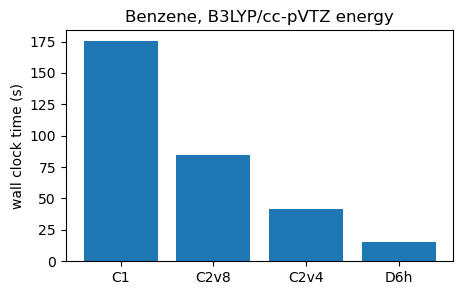

In [6]:
#| label: fig_benzene_timing
#| caption: Time for a B3LYP/cc-pVTZ energy calculation of benzene described with different symmetry.
times = {sym: gt.wall_time(log) for sym, log in timing_logs.items()}
energies = {sym: gt.final_energy(log) for sym, log in timing_logs.items()}

print(f"{'Symmetry':10s}{'unique atoms':>13}{'time (s)':>10}{'speed-up':>10}{'energy (hartree)':>20}")
for sym in SYMMETRIES:
    print(f"{sym:10s}{unique_atoms(INPUTS / f'benzene_{sym}_321.inp'):13d}{times[sym]:10.1f}"
          f"{times['C1'] / times[sym]:10.1f}{energies[sym]:20.10f}")

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(SYMMETRIES, [times[s] for s in SYMMETRIES], color="tab:blue")
ax.set_ylabel("wall clock time (s)")
ax.set_title("Benzene, B3LYP/cc-pVTZ energy")
plt.show()

The pattern is the same as in my 2021 table: the higher the symmetry, the faster the job, and the *D<sub>6h</sub>* job is several times faster than the *C<sub>1</sub>* job. Unlike in 2021, my two *C<sub>2v</sub>* versions did not take the same time this time: the one with the ring perpendicular to the *C<sub>2</sub>* axis (4 unique atoms) was about twice as fast as the one with the ring in a mirror plane (8 unique atoms). Timings also depend on what else the computer is doing (another *GAMESS* job was running on my computer during these tests), so run the jobs yourself with `RERUN = True` and see whether you get the same pattern.

Look closely at the energies. The *C<sub>1</sub>* and *C<sub>2v</sub>* energies agree to about 10<sup>–8</sup> hartree, but the *D<sub>6h</sub>* energy is about 2 &times; 10<sup>–5</sup> hartree higher. My 2021 table shows the same thing. That is not a different molecule: DFT methods calculate part of the energy on a grid of points around each atom, and the grid is not perfectly symmetric. A different orientation of the molecule gives a slightly different grid. 2 &times; 10<sup>–5</sup> hartree is 0.05 kJ/mol, far too small to matter in chemistry.

## Visualization of Molecular Orbitals

The molecular eigenvectors produced by the aug-cc-pCVTZ **basis set** included *f*-orbitals. This **huge number** of interacting atomic orbitals gives more accurate results, but it can complicate the **images** of molecular orbitals. The three bonding &pi;-MOs and the first two antibonding MOs were fine, but the highest level antibonding &pi;-MO (*&pi;<sub>6</sub>*) was mixed with even higher-level empty orbitals and did not have that “textbook” appearance. I performed the energy calculation again using a minimal basis set (STO-3G) and had far fewer molecular orbitals to choose from. The &pi;-MOs fit much better to the **textbook** idea. Am I sticking with a comfortable lie? Should I accept the truth?

Let us make both log files. The B3LYP/aug-cc-pCVTZ job uses *D<sub>6h</sub>* symmetry, so it takes a few minutes rather than an hour. `NPREO(1)=1,60` in the `$SCF` group asks *GAMESS* to print only the first 60 orbitals, not all 492. The STO-3G job takes about a second.

In [7]:
big_inp = energy_input("D6h", "DFTTYP=B3LYP ISPHER=1", "GBASIS=ACCTC", "B3LYP_ACCTC",
                       scf_keywords="NPREO(1)=1,60")
big_log = gt.run_gamess(big_inp, rerun=RERUN)

sto_inp = energy_input("D6h", "", "GBASIS=STO NGAUSS=3", "HF_STO3G")
sto_log = gt.run_gamess(sto_inp)

for log in (big_log, sto_log):
    gt.excerpt(log, "NUMBER OF CARTESIAN GAUSSIAN BASIS FUNCTIONS", after=0)

benzene_D6h_B3LYP_ACCTC: using existing benzene_D6h_B3LYP_ACCTC.log (rerun=True to run again)


benzene_D6h_HF_STO3G: finished normally (benzene_D6h_HF_STO3G.log)
  462   NUMBER OF CARTESIAN GAUSSIAN BASIS FUNCTIONS =  564
  408   NUMBER OF CARTESIAN GAUSSIAN BASIS FUNCTIONS =   36


The molecule lies in the *xy*-plane, so the &pi;-orbitals are built from *p<sub>z</sub>* functions. `gt.p_character(mo, "Z")` measures how much of each orbital is made of *p<sub>z</sub>* functions. The cell below lists every orbital (up to the 60 printed) that is mostly *p<sub>z</sub>*, with its *D<sub>6h</sub>* symmetry label.

In [8]:
def pi_orbitals(log_file, limit=0.5):
    mo = gt.molecular_orbitals(log_file)
    share = gt.p_character(mo, "Z")
    return mo, [n for n in range(len(mo["energies"])) if share[n] > limit], share

for name, log in [("HF/STO-3G", sto_log), ("B3LYP/aug-cc-pCVTZ", big_log)]:
    mo, pis, share = pi_orbitals(log)
    homo = gt.occupied_orbitals(log)
    print(f"{name}: {len(mo['energies'])} orbitals listed, HOMO = {homo}")
    for n in pis:
        print(f"   MO {n + 1:3d}  {mo['symmetries'][n]:4s} {mo['energies'][n]:9.4f} hartree"
              f"   pz share {share[n]:.2f}")

HF/STO-3G: 36 orbitals listed, HOMO = 21
   MO  17  A2U    -0.4625 hartree   pz share 1.00
   MO  20  E1G    -0.2837 hartree   pz share 1.00
   MO  21  E1G    -0.2837 hartree   pz share 1.00
   MO  22  E2U     0.2709 hartree   pz share 1.00
   MO  23  E2U     0.2709 hartree   pz share 1.00
   MO  24  B2G     0.5101 hartree   pz share 1.00
B3LYP/aug-cc-pCVTZ: 60 orbitals listed, HOMO = 21
   MO  17  A2U    -0.3729 hartree   pz share 1.00
   MO  20  E1G    -0.2578 hartree   pz share 0.99
   MO  21  E1G    -0.2578 hartree   pz share 0.99
   MO  22  E2U    -0.0128 hartree   pz share 0.99
   MO  23  E2U    -0.0128 hartree   pz share 0.99
   MO  29  A2U     0.0466 hartree   pz share 0.96
   MO  32  E1G     0.0690 hartree   pz share 0.77
   MO  33  E1G     0.0690 hartree   pz share 0.77
   MO  42  E2U     0.1108 hartree   pz share 0.98
   MO  43  E2U     0.1108 hartree   pz share 0.98
   MO  45  B2G     0.1217 hartree   pz share 0.99
   MO  48  B2G     0.1675 hartree   pz share 0.99
   MO  49

With STO-3G there are exactly six &pi;-orbitals, just as in SHMO: a<sub>2u</sub>, a degenerate pair of e<sub>1g</sub> (the HOMOs), a degenerate pair of e<sub>2u</sub> (the LUMOs) and b<sub>2g</sub>. With aug-cc-pCVTZ the first five look the same, but then the list keeps going: the diffuse functions make many more empty orbitals of &pi; symmetry, some of them only partly *p<sub>z</sub>*, and there is more than one b<sub>2g</sub> candidate for &pi;<sub>6</sub>. Which one is the “real” &pi;<sub>6</sub>? That is exactly the problem I met when making pictures.

If you find it difficult to **locate** the higher level antibonding MOs in a sea of extra orbitals then try repeating the energy calculation with a smaller basis set. It will be less accurate but may give **prettier pictures**. Open `runs/ch6/benzene_D6h_B3LYP_ACCTC.log` and `runs/ch6/benzene_D6h_HF_STO3G.log` in *MacMolPlt* and draw the orbitals listed above. {numref}`fig6_2C` presents the molecular orbitals produced from the two basis sets. Which do you prefer?

```{figure} images/ch6/pi-Benzene-3.png
---
width: 500px
name: fig6_2C
---
&pi;-MOs for benzene. The left-hand set is from the B3LYP/aug-cc-pCVTZ energy calculation and the right-hand set is from a HF/STO-3G energy calculation. Both sets were using the same optimized HF/3-21G geometry.
```

### Comparing with SHMO

In SHMO theory the six &pi;-orbitals of benzene have energies $\alpha + 2\beta$, $\alpha + \beta$ (twice), $\alpha - \beta$ (twice) and $\alpha - 2\beta$. Do the STO-3G orbital energies follow that pattern? *Python* can fit the best values of $\alpha$ and $\beta$ to the six energies with a straight line, $E = \alpha + x\beta$.

alpha = 0.004 hartree, beta = -0.255 hartree (-668 kJ/mol)


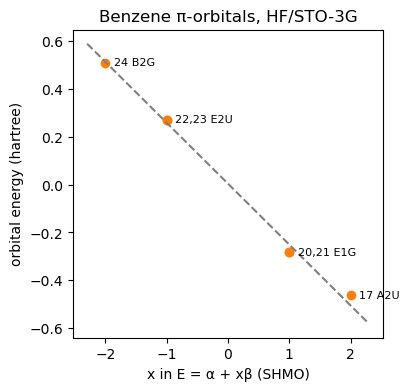

In [9]:
#| label: fig_benzene_huckel
#| caption: The six π-orbital energies of benzene from HF/STO-3G (dots) and the SHMO pattern with the best-fit α and β (lines).
mo, pis, share = pi_orbitals(sto_log)
x = np.array([2, 1, 1, -1, -1, -2])                    # SHMO: E = alpha + x*beta
energies_pi = np.array([mo["energies"][n] for n in pis])
beta, alpha = np.polyfit(x, energies_pi, 1)
print(f"alpha = {alpha:.3f} hartree, beta = {beta:.3f} hartree "
      f"({beta * HARTREE_TO_KJMOL:.0f} kJ/mol)")

fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(x, energies_pi, "o", color="tab:orange")
for xi in sorted(set(x)):                              # one label per (degenerate) level
    members = [n for xj, n in zip(x, pis) if xj == xi]
    label = ",".join(str(n + 1) for n in members) + " " + mo["symmetries"][members[0]]
    ax.annotate(label, (xi, mo["energies"][members[0]]), textcoords="offset points",
                xytext=(6, 0), va="center", fontsize=8)
xs = np.array([-2.3, 2.3])
ax.plot(xs, alpha + beta * xs, "--", color="gray")
ax.set_xlabel("x in E = α + xβ (SHMO)")
ax.set_ylabel("orbital energy (hartree)")
ax.set_title("Benzene π-orbitals, HF/STO-3G")
plt.show()

The STO-3G orbitals come in the same pattern of degeneracies and the same order as the SHMO orbitals, and the line is a reasonable fit. The points are not exactly on the line: the occupied orbitals and the empty orbitals of a Hartree-Fock calculation are not treated in the same way (the energy of an empty orbital is that of an extra electron that feels all the others), which SHMO ignores.

## Summary

We practiced **building** slightly larger molecules using symmetry in *MacMolPlt*. We then optimized the **structure** of benzene using different point groups. We compared the calculation time for an expensive energy calculation using the different symmetries and observed that **higher symmetry** gives faster results. We used *Python* to find the &pi;-orbitals in the log files and compared them with the SHMO pattern.

## Exercise

After reading the above discussion, use *MacMolPlt* to produce your **own versions** of the three symmetrical treatments of benzene above. Then build it without symmetry. You will have four versions of benzene structures at different symmetry. **Optimize** the structures at slightly higher theory than in this discussion (you could try HF/6-31G(d,p) or B3LYP/6-31G(d,p)).

Report the **bond lengths**. Open the result files in *MacMolPlt* and export **images** of the &pi;-MO system. Compare it to your results from the SHMO method.

```{tip}
The `bond_lengths()`, `energy_input()` and `pi_orbitals()` functions above work for your files too. For example, for HF/6-31G(d,p) use `"GBASIS=N31 NGAUSS=6 NDFUNC=1 NPFUNC=1"` as the basis keywords.
```

## AI Statement

This page was converted from the original Markdown page `6_Benzene.md` to a *Jupyter* notebook with the help of Claude (Anthropic), following the author's instructions.

- **Original text kept (about 65 %).** The introduction, learning goals, the building story, the structure comparison table, the author's 2021 timing table and its discussion, the discussion of orbital pictures, the summary, the exercise and all figures are the author's. Small edits: typos fixed (the table said *D<sub>3h</sub>* and the text said HF/6-31G where HF/3-21G was meant), and the hydrogen count of the aug-cc-pCVTZ basis was corrected from 24 to 25 functions so that the numbers add up to the stated 564.
- **Written by AI.** The four input files (the author's *MacMolPlt* files were not kept; the two *C<sub>2v</sub>* files use 4 and 8 unique atoms, not the 4 and 3 of the original builds), the settings cell, all code cells and the text that introduces them; the B3LYP/cc-pVTZ timing experiment that replaces the hour-long calculation; the note on DFT grid energies; the π-orbital search with `gt.p_character()`; the SHMO fit; the tip; and the helper `wall_time` in `gamess_tools.py`.
- **Changed workflow.** Jobs are run with `run_gamess()` instead of *GamessQ*; energy inputs are written from the optimized geometries by `new_input()`; bond lengths, timings and orbitals are read from the log files by *Python*. Slow jobs reuse the saved log files unless `RERUN = True`. *MacMolPlt* is still used to build the molecules and draw the orbitals.
- **Comparisons removed.** At the author's request, sentences and shell scripts that compared each step with the previous book's terminal and text-editor workflow were removed or rewritten, so the page reads as written for *Python*.